<a href="https://colab.research.google.com/github/Devikakrishnau/github-slideshow/blob/main/DL_LAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

EXP 1


Explain the basic image processing operations used in computer vision.
Write a Python program to perform the following operations on a given image:

Histogram Equalization

Thresholding

Edge Detection

Morphological Operations

Data Augmentation

Basic Image Processing Operations in Computer Vision

Image processing operations are fundamental techniques used to enhance, analyze, and extract meaningful information from images in computer vision systems.

1. Histogram Equalization

Explanation:
Histogram equalization improves the contrast of an image by redistributing pixel intensity values so that they are spread more uniformly across the histogram.

Purpose:

Enhances visibility in low-contrast images

Improves feature detection

2. Thresholding

Explanation:
Thresholding converts a grayscale image into a binary image by assigning pixels either black or white based on a threshold value.

Purpose:

Object separation

Image segmentation

3. Edge Detection

Explanation:
Edge detection identifies boundaries in an image where there is a sharp change in intensity.

Purpose:

Detect object outlines

Shape and feature extraction

Common methods: Sobel, Prewitt, Canny

4. Morphological Operations

Explanation:
Morphological operations process images based on shape using a structuring element.

Types:

Erosion: Removes noise

Dilation: Fills gaps

Opening: Erosion followed by dilation

Closing: Dilation followed by erosion

Purpose:

Noise removal

Shape refinement

5. Data Augmentation

Explanation:
Data augmentation artificially increases the size of a dataset by applying transformations to images.

Common techniques:

Rotation

Flipping

Scaling

Purpose:

Prevents overfitting

Improves model generalization

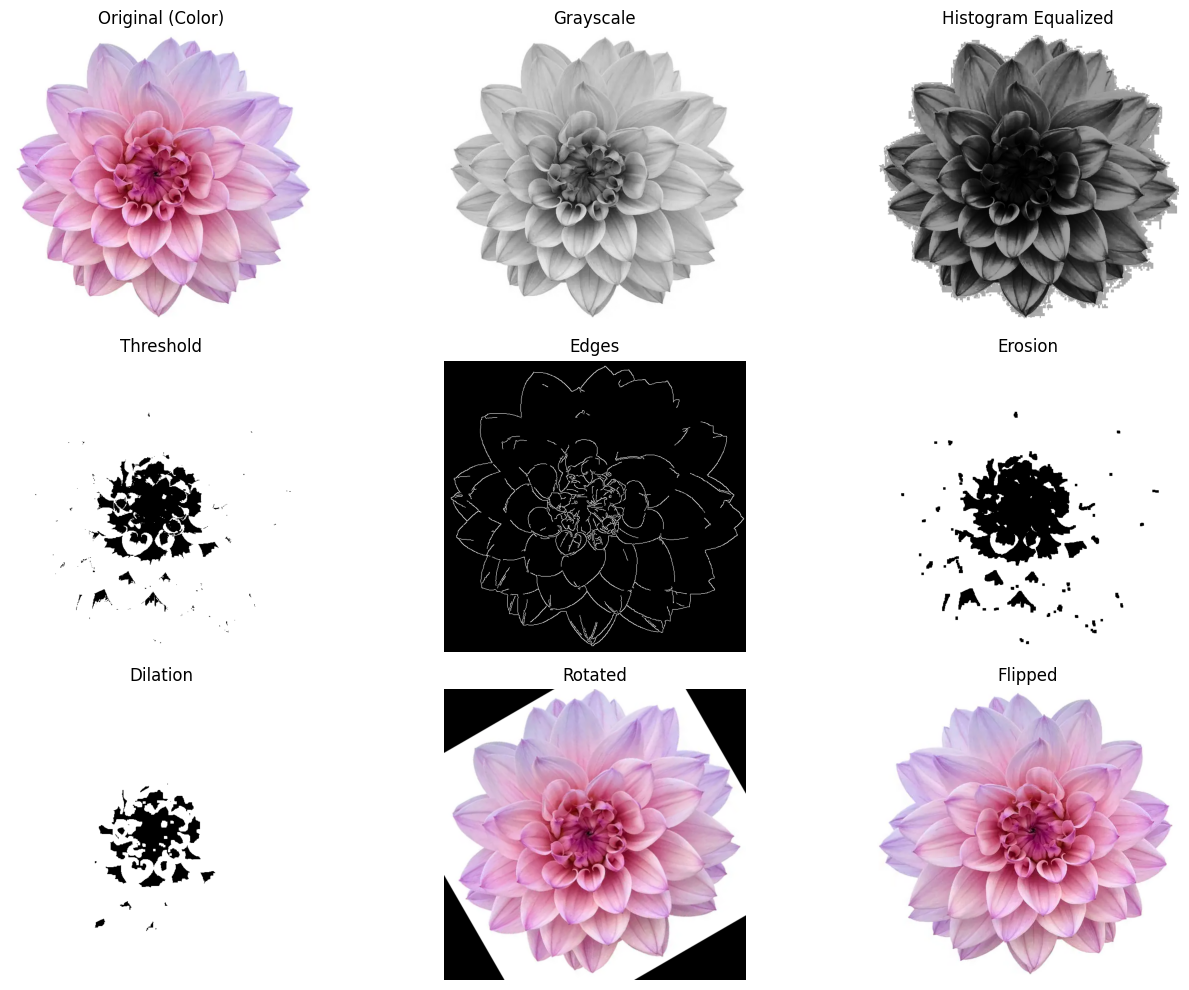

In [ ]:
import cv2                  # OpenCV library for image processing
import numpy as np          # NumPy for numerical operations
import matplotlib.pyplot as plt  # Matplotlib for displaying images

# -------------------------------
# Read the input image (COLOR)
# -------------------------------
img_color = cv2.imread('flower.webp')

# Convert color image to grayscale
img_gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)

# -------------------------------
# 1. Histogram Equalization
# Improves contrast of the grayscale image
# -------------------------------
hist_eq = cv2.equalizeHist(img_gray)

# -------------------------------
# 2. Thresholding
# Converts grayscale image to binary image
# -------------------------------
_, thresh = cv2.threshold(img_gray, 127, 255, cv2.THRESH_BINARY)

# -------------------------------
# 3. Edge Detection
# Detects edges using Canny algorithm
# -------------------------------
edges = cv2.Canny(img_gray, 100, 200)

# -------------------------------
# 4. Morphological Operations
# Used to remove noise and refine shapes
# -------------------------------
kernel = np.ones((5,5), np.uint8)  # Structuring element

# Erosion removes small white noises
erosion = cv2.erode(thresh, kernel, iterations=1)

# Dilation enlarges white regions
dilation = cv2.dilate(thresh, kernel, iterations=1)

# -------------------------------
# 5. Data Augmentation
# Creates new images from original image
# -------------------------------
(h, w) = img_color.shape[:2]

# Rotation: rotate image by 30 degrees
M = cv2.getRotationMatrix2D((w//2, h//2), 30, 1.0)
rotated = cv2.warpAffine(img_color, M, (w, h))

# Horizontal flip
flipped = cv2.flip(img_color, 1)

# Scaling (zoom)
scaled = cv2.resize(img_color, None, fx=1.2, fy=1.2)
scaled = scaled[0:h, 0:w]  # Crop to original size

# -------------------------------
# Display all results
# -------------------------------
titles = [
    'Original (Color)', 'Grayscale',
    'Histogram Equalized', 'Threshold',
    'Edges', 'Erosion',
    'Dilation', 'Rotated', 'Flipped'
]

images = [
    img_color, img_gray,
    hist_eq, thresh,
    edges, erosion,
    dilation, rotated, flipped
]

plt.figure(figsize=(14,10))

# Loop through images and display them
for i in range(len(images)):
    plt.subplot(3,3,i+1)

    # Display color images in RGB format
    if i in [0, 7, 8]:
        plt.imshow(cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB))
    else:
        plt.imshow(images[i], cmap='gray')

    plt.title(titles[i])
    plt.axis('off')  # Hide axis

plt.tight_layout()
plt.show()


EXP 2

Implement SVM / Softmax classifier for CIFAR-10 dataset using:
(i) K-Nearest Neighbors (KNN)
(ii) 3-Layer Neural Network

About CIFAR-10 Dataset

60,000 color images (32×32×3)

10 classes: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck

50,000 training images, 10,000 test images

PART (i): CIFAR-10 Classification using KNN
Explanation

KNN is a non-parametric classifier.
It classifies a test image based on the majority class of its K nearest neighbors using distance measures such as Euclidean distance.


KNN Advantages & Disadvantages

Advantages....

*Simple to understand
*No training phase

Disadvantages....

*Slow prediction
*High memory usage

In [ ]:
import numpy as np
from tensorflow.keras.datasets import cifar10
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Load CIFAR-10 dataset
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

# Flatten images (32x32x3 → 3072)
x_train = x_train.reshape(x_train.shape[0], -1)
x_test = x_test.reshape(x_test.shape[0], -1)

# Normalize data
x_train = x_train / 255.0
x_test = x_test / 255.0

# Use small subset (for speed in lab)
x_train_small = x_train[:5000]
y_train_small = y_train[:5000].ravel()
x_test_small = x_test[:1000]
y_test_small = y_test[:1000].ravel()

# KNN Classifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train_small, y_train_small)

# Prediction
y_pred = knn.predict(x_test_small)

# Accuracy
print("KNN Accuracy:", accuracy_score(y_test_small, y_pred))


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
KNN Accuracy: 0.266


PART (ii): CIFAR-10 using 3-Layer Neural Network (Softmax)
Explanation

A 3-layer neural network consists of:

Input layer

Hidden layer

Output layer with Softmax activation

Softmax converts outputs into class probabilities.

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical

# Load dataset
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

# Normalize
x_train = x_train / 255.0
x_test = x_test / 255.0

# One-hot encoding
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# 3-layer Neural Network
model = Sequential([
    Flatten(input_shape=(32,32,3)),  # Input layer
    Dense(128, activation='relu'),   # Hidden layer
    Dense(10, activation='softmax')  # Output layer
])

# Compile model
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train model
model.fit(x_train, y_train, epochs=5, batch_size=64, validation_split=0.1)

# Evaluate
test_loss, test_acc = model.evaluate(x_test, y_test)
print("Neural Network Accuracy:", test_acc)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - accuracy: 0.2661 - loss: 2.0407 - val_accuracy: 0.3544 - val_loss: 1.8477
Epoch 2/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.3716 - loss: 1.7668 - val_accuracy: 0.3720 - val_loss: 1.7296
Epoch 3/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.3960 - loss: 1.6969 - val_accuracy: 0.3826 - val_loss: 1.7213
Epoch 4/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.4093 - loss: 1.6769 - val_accuracy: 0.3872 - val_loss: 1.7112
Epoch 5/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.4202 - loss: 1.6303 - val_accuracy: 0.4140 - val_loss: 1.6549
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4164 - loss: 1.6356
Neural Network Accuracy: 0.41600000858306885


| Feature     | KNN   | 3-Layer NN |
| ----------- | ----- | ---------- |
| Training    | No    | Yes        |
| Speed       | Slow  | Fast       |
| Accuracy    | Lower | Higher     |
| Scalability | Poor  | Good       |


In [ ]:
#700 data , 5 class
#0: airplane
#1: automobile
#2: bird
#3: cat
#4: deer

#CIFAR-10 KNN (5 Classes, 500 Train + 200 Test per Class)

import numpy as np
from tensorflow.keras.datasets import cifar10
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Load CIFAR-10 dataset
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

# Combine train and test sets
X = np.concatenate((x_train, x_test), axis=0)
y = np.concatenate((y_train, y_test), axis=0).ravel()

# Select only 5 classes (0 to 4)
selected_classes = [0, 1, 2, 3, 4]

X_selected = []
y_selected = []

# Collect 700 samples per class
for cls in selected_classes:
    idx = np.where(y == cls)[0][:700]
    X_selected.append(X[idx])
    y_selected.append(y[idx])

X_selected = np.concatenate(X_selected)
y_selected = np.concatenate(y_selected)

# Flatten images (32x32x3 → 3072)
X_selected = X_selected.reshape(X_selected.shape[0], -1)

# Normalize pixel values
X_selected = X_selected / 255.0

# Split into training and testing
X_train = []
y_train = []
X_test = []
y_test = []

for i, cls in enumerate(selected_classes):
    start = i * 700
    X_train.append(X_selected[start:start+500])
    y_train.append(y_selected[start:start+500])
    X_test.append(X_selected[start+500:start+700])
    y_test.append(y_selected[start+500:start+700])

X_train = np.concatenate(X_train)
y_train = np.concatenate(y_train)
X_test = np.concatenate(X_test)
y_test = np.concatenate(y_test)

# KNN Classifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

# Prediction
y_pred = knn.predict(X_test)

# Accuracy
print("KNN Accuracy (5 classes):", accuracy_score(y_test, y_pred))

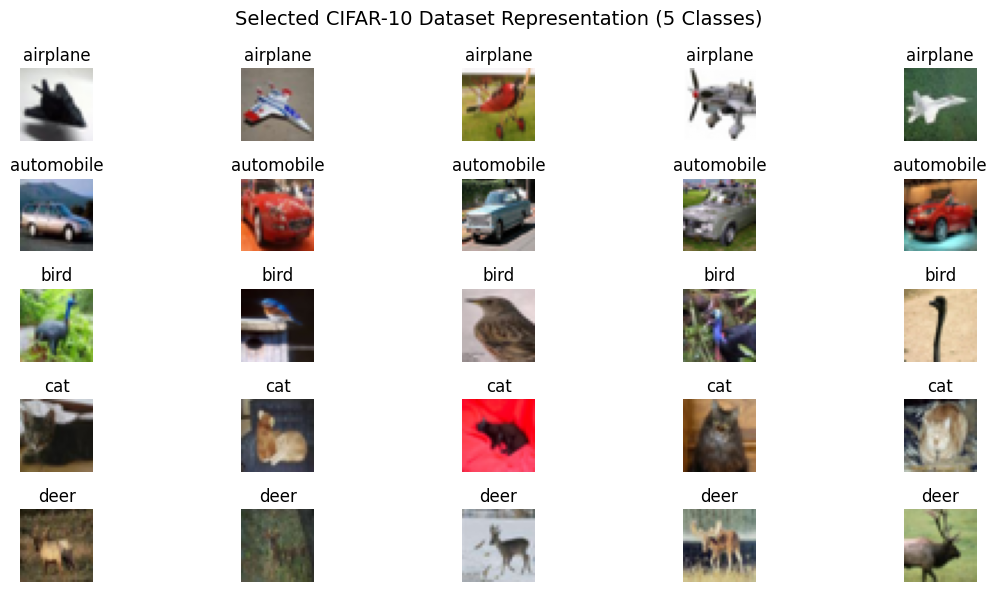

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# CIFAR-10 class names
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

plt.figure(figsize=(12, 6))

for i, cls in enumerate(selected_classes):
    # pick 5 images from each class
    class_indices = np.where(y_selected == cls)[0][:5]

    for j, idx in enumerate(class_indices):
        plt.subplot(5, 5, i*5 + j + 1)
        # Reshape the flattened image back to 32x32x3 for display
        reshaped_image = X_selected[idx].reshape(32, 32, 3)
        plt.imshow(reshaped_image)
        plt.title(class_names[cls])
        plt.axis('off')

plt.suptitle("Selected CIFAR-10 Dataset Representation (5 Classes)", fontsize=14)
plt.tight_layout()
plt.show()

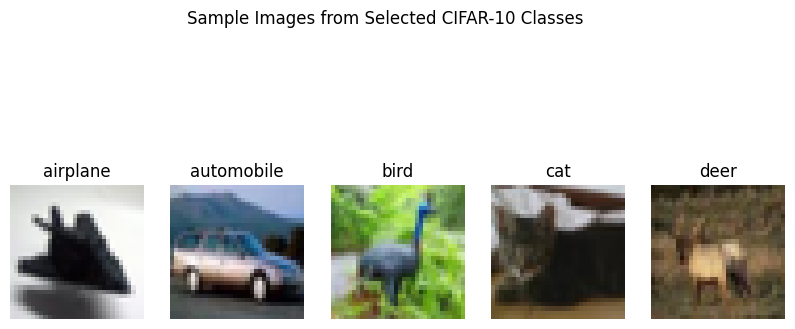

Epoch 1/5
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.2931 - loss: 2.3406 - val_accuracy: 0.0040 - val_loss: 1.9935
Epoch 2/5
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.4637 - loss: 1.3629 - val_accuracy: 0.0080 - val_loss: 2.5681
Epoch 3/5
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.4604 - loss: 1.3286 - val_accuracy: 0.2880 - val_loss: 1.5478
Epoch 4/5
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5022 - loss: 1.2697 - val_accuracy: 0.0400 - val_loss: 2.4111
Epoch 5/5
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.5309 - loss: 1.2398 - val_accuracy: 0.5520 - val_loss: 1.2145
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6145 - loss: 1.0779
Neural Network Accuracy (5 classes): 0.5130000114440918


In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical

# Load CIFAR-10 dataset
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

# Combine train and test sets
X = np.concatenate((x_train, x_test), axis=0)
y = np.concatenate((y_train, y_test), axis=0).ravel()

# CIFAR-10 class names
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

# Select 5 classes
selected_classes = [0, 1, 2, 3, 4]

# --------------------------------
# Display dataset samples
# --------------------------------
plt.figure(figsize=(10,5))
for i, cls in enumerate(selected_classes):
    idx = np.where(y == cls)[0][0]
    plt.subplot(1,5,i+1)
    plt.imshow(X[idx])
    plt.title(class_names[cls])
    plt.axis('off')

plt.suptitle("Sample Images from Selected CIFAR-10 Classes")
plt.show()

# --------------------------------
# Select 700 samples per class
# --------------------------------
X_selected = []
y_selected = []

for cls in selected_classes:
    idx = np.where(y == cls)[0][:700]
    X_selected.append(X[idx])
    y_selected.append(y[idx])

X_selected = np.concatenate(X_selected)
y_selected = np.concatenate(y_selected)

# Normalize images
X_selected = X_selected / 255.0

# Split into train (500) and test (200)
X_train, y_train, X_test, y_test = [], [], [], []

for i in range(len(selected_classes)):
    start = i * 700
    X_train.append(X_selected[start:start+500])
    y_train.append(y_selected[start:start+500])
    X_test.append(X_selected[start+500:start+700])
    y_test.append(y_selected[start+500:start+700])

X_train = np.concatenate(X_train)
X_test = np.concatenate(X_test)
y_train = np.concatenate(y_train)
y_test = np.concatenate(y_test)

# One-hot encoding (5 classes)
y_train = to_categorical(y_train, 5)
y_test = to_categorical(y_test, 5)

# --------------------------------
# 3-layer Neural Network
# --------------------------------
model = Sequential([
    Flatten(input_shape=(32,32,3)),
    Dense(128, activation='relu'),
    Dense(5, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train model
model.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.1)

# Evaluate model
test_loss, test_acc = model.evaluate(X_test, y_test)
print("Neural Network Accuracy (5 classes):", test_acc)


EXP 3

Study the effect of Batch Normalization and Dropout in a Neural Network Classifier

Aim

To study how Batch Normalization and Dropout affect the performance, training speed, and generalization of a neural network classifier.

Theory
1. Batch Normalization

Definition:
Batch Normalization normalizes the activations of each layer to have zero mean and unit variance during training.

Why it is used:

Reduces internal covariate shift

Speeds up training

Allows higher learning rates

Improves stability

Where it is applied:
Between a Dense/Conv layer and its activation function.

2. Dropout

Definition:
Dropout randomly disables a fraction of neurons during training.

Why it is used:

Prevents overfitting

Improves generalization

Forces network to learn robust features

Dropout rate:

0.2 → drop 20% neurons

0.5 → drop 50% neurons

Experiment Setup

We train two neural network models:

Without Batch Normalization and Dropout

With Batch Normalization and Dropout

In [ ]:
#Model 1: Without BatchNorm & Dropout

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt

# Load data
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

# Normalize
x_train, x_test = x_train/255.0, x_test/255.0

# One-hot encoding
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# Model without BN & Dropout
model1 = Sequential([
    Flatten(input_shape=(32,32,3)),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model1.compile(optimizer='adam',
               loss='categorical_crossentropy',
               metrics=['accuracy'])

model1.fit(x_train, y_train, epochs=5, batch_size=64)

loss1, acc1 = model1.evaluate(x_test, y_test)
print("Accuracy without BN & Dropout:", acc1)


Epoch 1/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.2775 - loss: 2.0309
Epoch 2/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.3824 - loss: 1.7445
Epoch 3/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.4048 - loss: 1.6722
Epoch 4/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.4241 - loss: 1.6274
Epoch 5/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.4336 - loss: 1.5866
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4301 - loss: 1.5973
Accuracy without BN & Dropout: 0.42989999055862427


In [ ]:
#Model 2: With Batch Normalization & Dropout

from tensorflow.keras.layers import BatchNormalization, Dropout

model2 = Sequential([
    Flatten(input_shape=(32,32,3)),
    Dense(128),
    BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

model2.compile(optimizer='adam',
               loss='categorical_crossentropy',
               metrics=['accuracy'])

model2.fit(x_train, y_train, epochs=5, batch_size=64)

loss2, acc2 = model2.evaluate(x_test, y_test)
print("Accuracy with BN & Dropout:", acc2)



Epoch 1/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.2980 - loss: 2.0466
Epoch 2/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.4044 - loss: 1.7015
Epoch 3/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.4184 - loss: 1.6521
Epoch 4/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 17s 9ms/step - accuracy: 0.4350 - loss: 1.6075
Epoch 5/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.4450 - loss: 1.5891
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4373 - loss: 1.5700
Accuracy with BN & Dropout: 0.4381999969482422


In [ ]:
#Model 2: With Batch Normalization & Dropout

from tensorflow.keras.layers import BatchNormalization, Dropout

model2 = Sequential([
    Flatten(input_shape=(32,32,3)),
    Dense(128),
    BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    Dropout(0.2),
    Dense(10, activation='softmax')
])

model2.compile(optimizer='adam',
               loss='categorical_crossentropy',
               metrics=['accuracy'])

model2.fit(x_train, y_train, epochs=5, batch_size=64)

loss2, acc2 = model2.evaluate(x_test, y_test)
print("Accuracy with BN & Dropout:", acc2)



Epoch 1/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.3484 - loss: 1.8592
Epoch 2/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.4455 - loss: 1.5801
Epoch 3/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.4699 - loss: 1.5108
Epoch 4/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.4919 - loss: 1.4598
Epoch 5/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.5001 - loss: 1.4242
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4224 - loss: 1.6843
Accuracy with BN & Dropout: 0.41519999504089355


/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
391/391 ━━━━━━━━━━━━━━━━━━━━ 11s 24ms/step - accuracy: 0.2593 - loss: 2.0676 - val_accuracy: 0.3753 - val_loss: 1.7449
Epoch 2/5
391/391 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.3855 - loss: 1.7251 - val_accuracy: 0.4155 - val_loss: 1.6576
Epoch 3/5
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.4170 - loss: 1.6342 - val_accuracy: 0.4207 - val_loss: 1.6446
Epoch 4/5
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.4385 - loss: 1.5798 - val_accuracy: 0.4410 - val_loss: 1.5644
Epoch 5/5
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.4568 - loss: 1.5178 - val_accuracy: 0.4643 - val_loss: 1.5031
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4652 - loss: 1.5004
Epoch 1/5
391/391 ━━━━━━━━━━━━━━━━━━━━ 13s 27ms/step - accuracy: 0.3335 - loss: 1.8899 - val_accuracy: 0.3049 - val_loss: 1.9565
Epoch 2/5
391/391 ━━━━━━━━━━━━━━━━━━━━ 10s 24ms/step - accuracy: 0.4483 - loss: 1.5518 - val_accuracy: 0.4574 - val_loss: 1.5307
Epoch 3/5
391/391 ━━━━━━━━

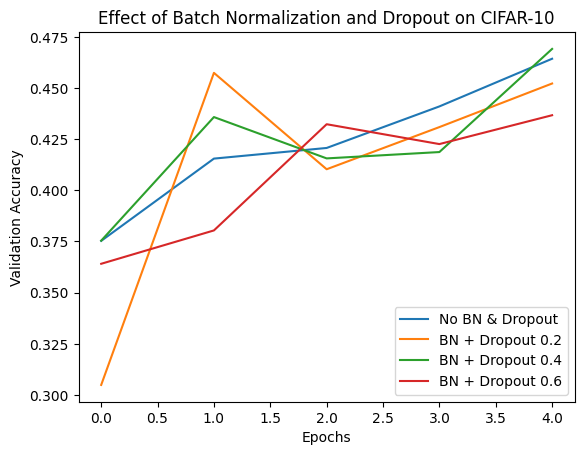

No BN & Dropout       : 0.4643000066280365
BN + Dropout 0.2      : 0.4521999955177307
BN + Dropout 0.4      : 0.4690999984741211
BN + Dropout 0.6      : 0.4366999864578247


In [ ]:
# Study the effect of Batch Normalization and Dropout on CIFAR-10

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.layers import Dense, Flatten, Dropout, BatchNormalization
from tensorflow.keras.models import Sequential

# Load CIFAR-10 dataset
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

# Normalize data
x_train = x_train / 255.0
x_test = x_test / 255.0

# One-hot encode labels
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# -------------------------------
# Model 1: No BatchNorm & Dropout
# -------------------------------
model1 = Sequential([
    Flatten(input_shape=(32, 32, 3)),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model1.compile(optimizer='adam',
               loss='categorical_crossentropy',
               metrics=['accuracy'])

history1 = model1.fit(
    x_train, y_train,
    epochs=5,
    batch_size=128,
    validation_data=(x_test, y_test)
)

acc1 = model1.evaluate(x_test, y_test)[1]

# -------------------------------
# Model 2: BN + Dropout (0.2)
# -------------------------------
model2 = Sequential([
    Flatten(input_shape=(32, 32, 3)),
    Dense(256),
    BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    Dropout(0.2),
    Dense(128),
    BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    Dropout(0.2),
    Dense(10, activation='softmax')
])

model2.compile(optimizer='adam',
               loss='categorical_crossentropy',
               metrics=['accuracy'])

history2 = model2.fit(
    x_train, y_train,
    epochs=5,
    batch_size=128,
    validation_data=(x_test, y_test)
)

acc2 = model2.evaluate(x_test, y_test)[1]

# -------------------------------
# Model 3: BN + Dropout (0.4)
# -------------------------------
model3 = Sequential([
    Flatten(input_shape=(32, 32, 3)),
    Dense(256),
    BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    Dropout(0.4),
    Dense(128),
    BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    Dropout(0.4),
    Dense(10, activation='softmax')
])

model3.compile(optimizer='adam',
               loss='categorical_crossentropy',
               metrics=['accuracy'])

history3 = model3.fit(
    x_train, y_train,
    epochs=5,
    batch_size=128,
    validation_data=(x_test, y_test)
)

acc3 = model3.evaluate(x_test, y_test)[1]

# -------------------------------
# Model 4: BN + Dropout (0.6)
# -------------------------------
model4 = Sequential([
    Flatten(input_shape=(32, 32, 3)),
    Dense(256),
    BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    Dropout(0.6),
    Dense(128),
    BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    Dropout(0.6),
    Dense(10, activation='softmax')
])

model4.compile(optimizer='adam',
               loss='categorical_crossentropy',
               metrics=['accuracy'])

history4 = model4.fit(
    x_train, y_train,
    epochs=5,
    batch_size=128,
    validation_data=(x_test, y_test)
)

acc4 = model4.evaluate(x_test, y_test)[1]

# -------------------------------
# Accuracy Comparison Plot
# -------------------------------
plt.figure()
plt.plot(history1.history['val_accuracy'], label='No BN & Dropout')
plt.plot(history2.history['val_accuracy'], label='BN + Dropout 0.2')
plt.plot(history3.history['val_accuracy'], label='BN + Dropout 0.4')
plt.plot(history4.history['val_accuracy'], label='BN + Dropout 0.6')
plt.xlabel('Epochs')
plt.ylabel('Validation Accuracy')
plt.title('Effect of Batch Normalization and Dropout on CIFAR-10')
plt.legend()
plt.show()

# -------------------------------
# Final Accuracy Values
# -------------------------------
print("No BN & Dropout       :", acc1)
print("BN + Dropout 0.2      :", acc2)
print("BN + Dropout 0.4      :", acc3)
print("BN + Dropout 0.6      :", acc4)


Layer Normalization

Definition:
Layer Normalization (LN) is a normalization technique where the activations of a single data sample are normalized across the features (neurons) of a layer, instead of across a mini-batch.

How Layer Normalization Works

For one input sample in a layer:

Compute mean and variance over all neurons in that layer

Normalize each neuron output

Key Characteristics

Normalization is independent of batch size

Same behavior during training and testing

Suitable for sequential and recurrent models

Advantages

Works well with small batch sizes

Stable training for RNNs, LSTMs, Transformers

No dependency on batch statistics

Improves convergence consistency

Disadvantages

Slightly slower than Batch Normalization

Less effective for CNNs compared to Batch Normalization

EXP 4

  Familiarization of Image Labelling Tools for Object Detection and Segmentation

Aim

To study and familiarize with different image annotation (labelling) tools used for creating datasets for object detection and image segmentation tasks in computer vision.

Introduction

Image labelling is the process of annotating images with meaningful information such as bounding boxes, polygons, or pixel-wise labels. These labelled datasets are essential for training supervised deep learning models in applications like autonomous driving, medical imaging, surveillance, and robotics.

Types of Image Labelling....

Object Detection:

Labels objects using bounding boxes

Output: class label + box coordinates

Example: car, person, traffic sign

Image Segmentation:

Labels each pixel in the image

Types:

Semantic Segmentation – same label for same object class

Instance Segmentation – different labels for each object instance


Popular Image Labelling Tools...

1. LabelImg

Used for object detection

Supports bounding box annotation

Output formats: YOLO (.txt), Pascal VOC (.xml)

2. CVAT (Computer Vision Annotation Tool)

Web-based and open-source

Supports bounding boxes, polygons, polylines

Used for object detection and segmentation

3. LabelMe

Polygon-based annotation tool

Mainly used for semantic segmentation

Stores annotations in JSON format

4. VGG Image Annotator (VIA)

Lightweight, browser-based tool

No installation required

Supports regions, points, and polygons

General Steps in Image Labelling....

Collect image dataset

Load images into annotation tool

Choose annotation type (box/polygon)

Assign class labels

Save annotations in required format

Split dataset into training and testing sets

Annotation Formats and Usage....
Format	Used For
XML (Pascal VOC)	Faster R-CNN
TXT (YOLO)	YOLO models
JSON	Mask R-CNN, segmentation

Applications....

Autonomous vehicles

Medical image analysis

Traffic monitoring

Face and object detection

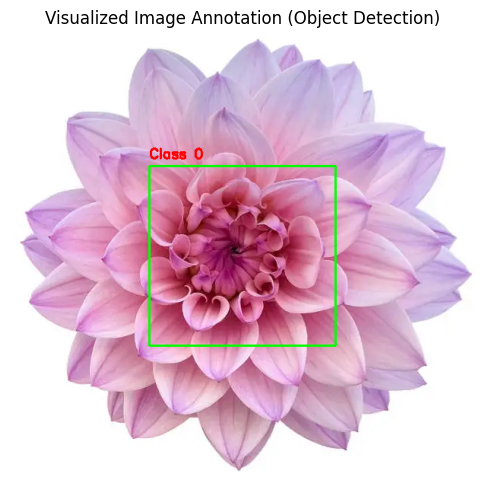

In [ ]:
import cv2
import matplotlib.pyplot as plt

# -----------------------------
# Load Image
# -----------------------------
image_path = "/content/flower.webp"   # make sure this image exists in Colab
label_path = "/content/sample.txt"    # annotation file (will be created)

image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

h, w, _ = image.shape

# -----------------------------
# Create a SAMPLE YOLO annotation
# Format: class_id x_center y_center width height (normalized)
# -----------------------------
with open(label_path, "w") as f:
    f.write("0 0.5 0.5 0.4 0.4")  # one bounding box at center

# -----------------------------
# Read YOLO Annotation
# -----------------------------
with open(label_path, "r") as f:
    lines = f.readlines()

for line in lines:
    class_id, x_center, y_center, bw, bh = map(float, line.split())

    # Convert YOLO format to pixel values
    x_center *= w
    y_center *= h
    bw *= w
    bh *= h

    x1 = int(x_center - bw / 2)
    y1 = int(y_center - bh / 2)
    x2 = int(x_center + bw / 2)
    y2 = int(y_center + bh / 2)

    # Draw bounding box
    cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
    cv2.putText(
        image,
        f"Class {int(class_id)}",
        (x1, y1 - 10),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (255, 0, 0),
        2
    )

# -----------------------------
# Display Image
# -----------------------------
plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.title("Visualized Image Annotation (Object Detection)")
plt.axis("off")
plt.show()


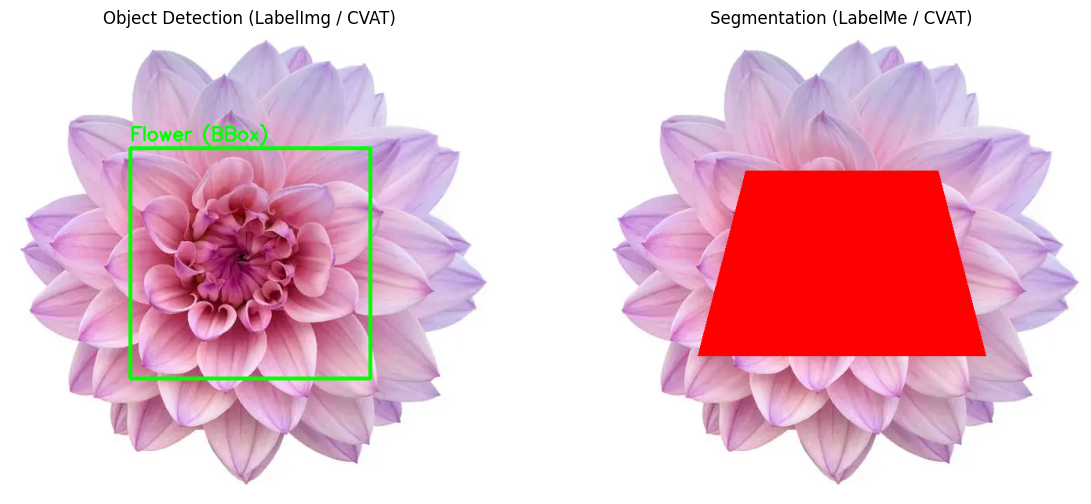

In [ ]:
# =========================================
# Representation of Image Labelling Tools
# Image: /content/flower.webp
# =========================================

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load given image
img_path = "/content/flower.webp"
image = cv2.imread(img_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

H, W, _ = image.shape

# -----------------------------------------
# 1️⃣ OBJECT DETECTION (LabelImg / CVAT)
# Bounding Box Representation
# -----------------------------------------
det_image = image.copy()

# Simulated YOLO annotation (flower object)
# class_id, x_center, y_center, width, height (normalized)
x, y, w, h = 0.5, 0.5, 0.5, 0.5

x_c, y_c = int(x * W), int(y * H)
bw, bh = int(w * W), int(h * H)

x1, y1 = x_c - bw // 2, y_c - bh // 2
x2, y2 = x_c + bw // 2, y_c + bh // 2

cv2.rectangle(det_image, (x1, y1), (x2, y2), (0,255,0), 3)
cv2.putText(det_image, "Flower (BBox)",
            (x1, y1-10), cv2.FONT_HERSHEY_SIMPLEX,
            0.8, (0,255,0), 2)

# -----------------------------------------
# 2️⃣ SEGMENTATION (LabelMe / CVAT)
# Polygon + Mask Representation
# -----------------------------------------
seg_image = image.copy()

# Example polygon around flower
polygon = np.array([
    [W*0.3, H*0.3],
    [W*0.7, H*0.3],
    [W*0.8, H*0.7],
    [W*0.2, H*0.7]
], dtype=np.int32)

mask = np.zeros((H, W), dtype=np.uint8)
cv2.fillPoly(mask, [polygon], 255)

# Overlay mask
seg_image[mask == 255] = [255, 0, 0]

# -----------------------------------------
# Display Results
# -----------------------------------------
plt.figure(figsize=(14,6))

plt.subplot(1,2,1)
plt.title("Object Detection (LabelImg / CVAT)")
plt.imshow(det_image)
plt.axis("off")

plt.subplot(1,2,2)
plt.title("Segmentation (LabelMe / CVAT)")
plt.imshow(seg_image)
plt.axis("off")

plt.show()



EXP 5

Study of Object Detection and Segmentation Models (Mask R-CNN, U-Net, SegNet)


Aim

To study and compare popular deep learning models used for object detection and image segmentation, namely Mask R-CNN, U-Net, and SegNet.

Introduction

Object detection and image segmentation are core tasks in computer vision.

Object detection identifies what objects are present and where.

Segmentation classifies each pixel in an image.

Different models are designed based on accuracy needs, computational cost, and application domain.


1. Mask R-CNN

Extends Faster R-CNN by adding a segmentation mask branch

Performs:

Object detection

Classification

Instance segmentation

Widely used in autonomous driving and medical imaging

Key features

Region Proposal Network (RPN)

RoI Align

Pixel-level masks for each object

2. U-Net

Encoder–decoder architecture with skip connections

Designed mainly for semantic segmentation

Very effective with small datasets

Key features

Downsampling (encoder)

Upsampling (decoder)

Skip connections preserve spatial details

3. SegNet

Encoder–decoder network

Uses max-pooling indices for upsampling

Memory efficient compared to U-Net

Key features

No fully connected layers

Suitable for road scene segmentation



Using image directory: jpg


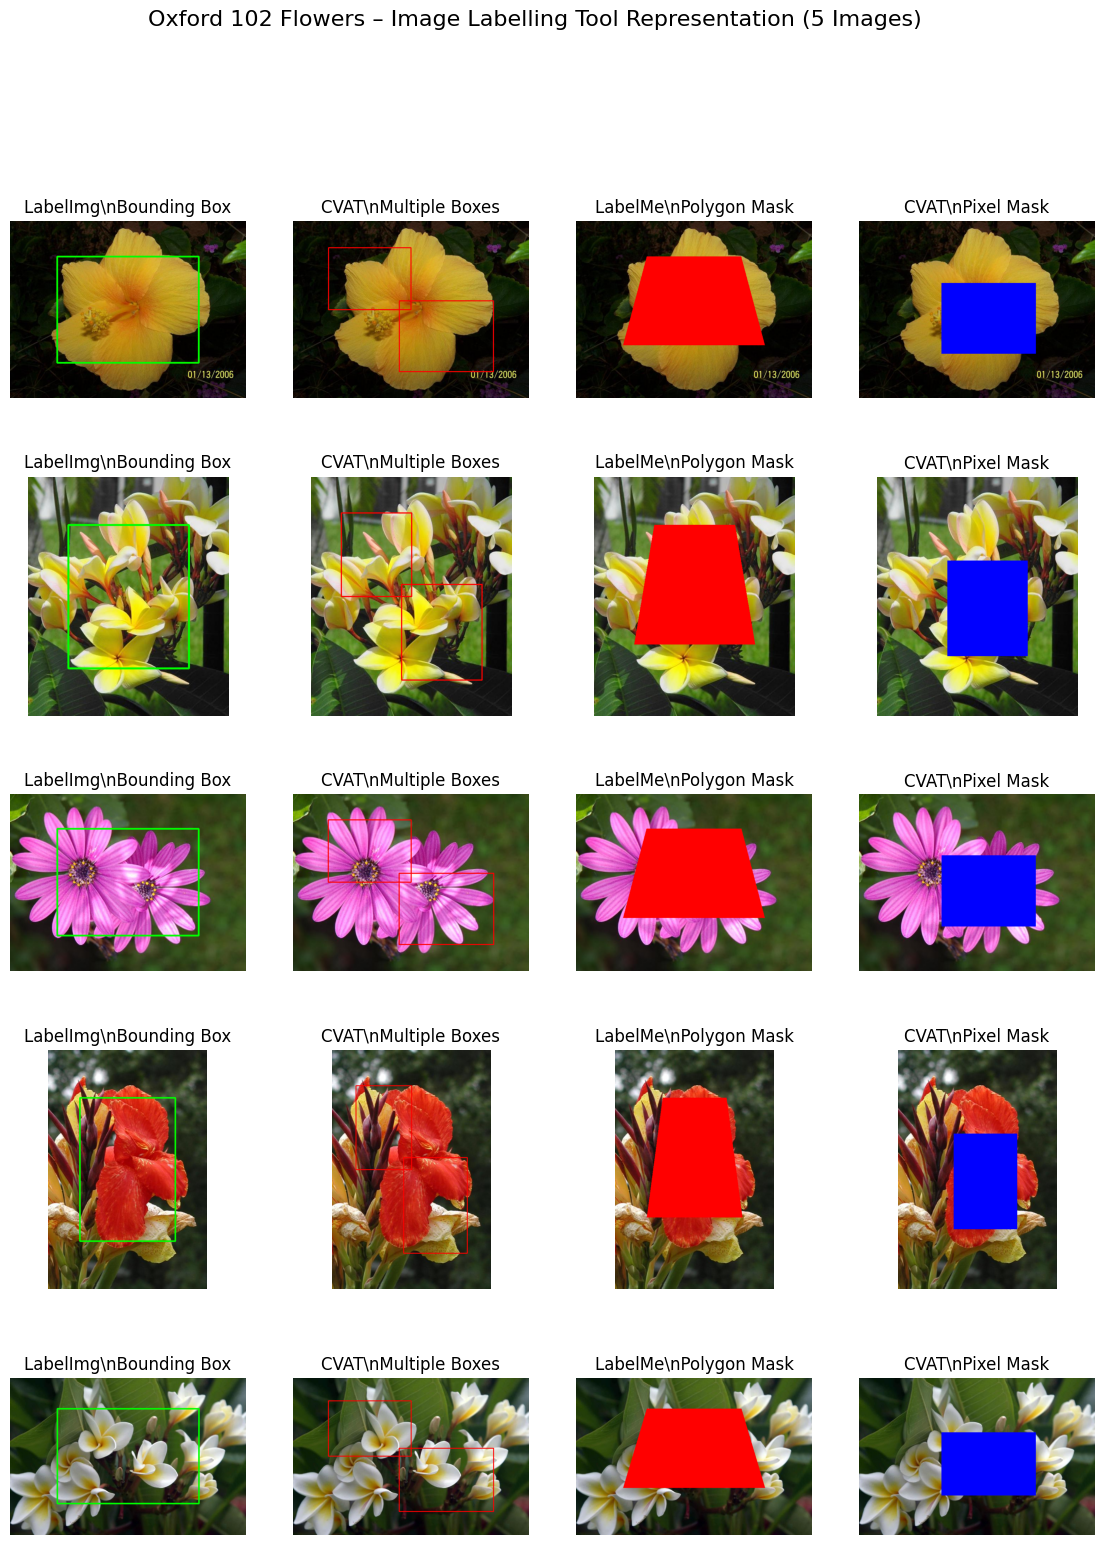

In [ ]:
import os
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt
import scipy.io as sio
import tarfile
import urllib.request
import shutil # Import shutil for removing directories

# -----------------------------
# Download Oxford 102 (images)
# -----------------------------
extracted_folder_name = "102flowers"
img_subfolder_name = "jpg"
# Define two possible locations for the image directory
expected_img_dir_full_path = os.path.join(extracted_folder_name, img_subfolder_name) # e.g., 102flowers/jpg
expected_img_dir_flat_path = img_subfolder_name # e.g., jpg

final_img_dir = None

# Check if either expected path exists
if os.path.exists(expected_img_dir_full_path):
    final_img_dir = expected_img_dir_full_path
elif os.path.exists(expected_img_dir_flat_path):
    final_img_dir = expected_img_dir_flat_path

# If neither exists, then perform download and extraction
if final_img_dir is None:
    print(f"Neither '{expected_img_dir_full_path}' nor '{expected_img_dir_flat_path}' found. Attempting to download and extract.")

    # Clean up any potentially partially extracted directories
    if os.path.exists(extracted_folder_name):
        print(f"Removing existing folder: {extracted_folder_name}")
        shutil.rmtree(extracted_folder_name)
    if os.path.exists(expected_img_dir_flat_path): # Check if 'jpg' exists directly too
        print(f"Removing existing folder: {expected_img_dir_flat_path}")
        shutil.rmtree(expected_img_dir_flat_path)

    url = "https://www.robots.ox.ac.uk/~vgg/data/flowers/102/102flowers.tgz"
    archive_name = "102flowers.tgz"

    if not os.path.exists(archive_name):
        print(f"Downloading {archive_name}...")
        urllib.request.urlretrieve(url, archive_name)
    else:
        print(f"{archive_name} already exists. Skipping download.")

    print(f"Extracting {archive_name}...")
    with tarfile.open(archive_name) as tar:
        # Add filter='data' for robustness in newer Python versions, though not strictly needed for 3.12
        # For Python 3.12, can just leave as is, the warning is for future compatibility.
        tar.extractall()
    print("Extraction complete.")

    # After extraction, try to determine the final_img_dir again
    if os.path.exists(expected_img_dir_full_path):
        final_img_dir = expected_img_dir_full_path
elif os.path.exists(expected_img_dir_flat_path):
        final_img_dir = expected_img_dir_flat_path

# Final check to ensure we found an image directory
if final_img_dir is None:
    raise FileNotFoundError(f"Failed to find image directory after extraction. Looked for '{expected_img_dir_full_path}' and '{expected_img_dir_flat_path}'.")
else:
    print(f"Using image directory: {final_img_dir}")


all_images = sorted(os.listdir(final_img_dir))
sample_images = random.sample(all_images, 5)

fig, axs = plt.subplots(5, 4, figsize=(14, 18))

for i, img_name in enumerate(sample_images):
    img_path = os.path.join(final_img_dir, img_name)
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    H, W, _ = img.shape

    # -----------------------------------------
    # 1️⃣ LabelImg – Object Detection
    # Single Bounding Box
    # -----------------------------------------
    labelimg_img = img.copy()
    cv2.rectangle(labelimg_img,
                  (int(0.2*W), int(0.2*H)),
                  (int(0.8*W), int(0.8*H)),
                  (0, 255, 0), 3)

    # -----------------------------------------
    # 2️⃣ CVAT – Object Detection
    # Multiple Bounding Boxes
    # -----------------------------------------
    cvat_det_img = img.copy()
    cv2.rectangle(cvat_det_img,
                  (int(0.15*W), int(0.15*H)),
                  (int(0.5*W), int(0.5*H)),
                  (255, 0, 0), 2)
    cv2.rectangle(cvat_det_img,
                  (int(0.45*W), int(0.45*H)),
                  (int(0.85*W), int(0.85*H)),
                  (255, 0, 0), 2)

    # -----------------------------------------
    # 3️⃣ LabelMe – Segmentation
    # Polygon Mask
    # -----------------------------------------
    labelme_img = img.copy()
    polygon = np.array([
        [int(0.3*W), int(0.2*H)],
        [int(0.7*W), int(0.2*H)],
        [int(0.8*W), int(0.7*H)],
        [int(0.2*W), int(0.7*H)]
    ])
    mask = np.zeros((H, W), dtype=np.uint8)
    cv2.fillPoly(mask, [polygon], 255)
    labelme_img[mask == 255] = [255, 0, 0]   # red region

    # -----------------------------------------
    # 4️⃣ CVAT – Segmentation
    # Pixel-wise Mask
    # -----------------------------------------
    cvat_seg_img = img.copy()
    cvat_seg_img[int(0.35*H):int(0.75*H),
                 int(0.35*W):int(0.75*W)] = [0, 0, 255]  # blue mask

    # -----------------------------------------
    # Plot
    # -----------------------------------------
    axs[i, 0].imshow(labelimg_img)
    axs[i, 0].set_title("LabelImg\\nBounding Box")

    axs[i, 1].imshow(cvat_det_img)
    axs[i, 1].set_title("CVAT\\nMultiple Boxes")

    axs[i, 2].imshow(labelme_img)
    axs[i, 2].set_title("LabelMe\\nPolygon Mask")

    axs[i, 3].imshow(cvat_seg_img)
    axs[i, 3].set_title("CVAT\\nPixel Mask")

    for j in range(4):
        axs[i, j].axis("off")

plt.suptitle("Oxford 102 Flowers – Image Labelling Tool Representation (5 Images)",
             fontsize=16)
plt.show()

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MaskRCNN_ResNet50_FPN_Weights.COCO_V1`. You can also use `weights=MaskRCNN_ResNet50_FPN_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:01<00:00, 137MB/s]


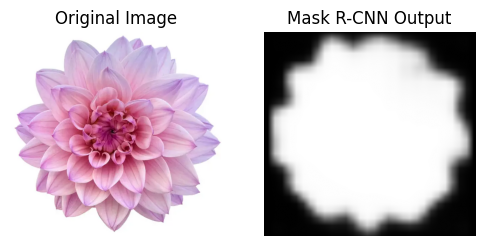

In [ ]:
# -------------------------------
# MASK R-CNN (Object Detection + Instance Segmentation)
# -------------------------------
import torch
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt
from PIL import Image

# Load pretrained Mask R-CNN
model = torchvision.models.detection.maskrcnn_resnet50_fpn(pretrained=True)
model.eval()

# Load image
image = Image.open("/content/flower.webp").convert("RGB")
transform = transforms.ToTensor()
img_tensor = transform(image)

# Inference
with torch.no_grad():
    prediction = model([img_tensor])

# Display first detected mask
mask = prediction[0]['masks'][0, 0].numpy()

plt.figure(figsize=(6,4))
plt.subplot(1,2,1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(mask, cmap="gray")
plt.title("Mask R-CNN Output")
plt.axis("off")

plt.show()


In [ ]:
# -------------------------------
# U-NET MODEL (Semantic Segmentation)
# -------------------------------
import tensorflow as tf
from tensorflow.keras.layers import *
from tensorflow.keras.models import Model

def UNet(input_shape=(128,128,3)):
    inputs = Input(input_shape)

    # Encoder
    c1 = Conv2D(64, 3, activation='relu', padding='same')(inputs)
    p1 = MaxPooling2D()(c1)

    c2 = Conv2D(128, 3, activation='relu', padding='same')(p1)
    p2 = MaxPooling2D()(c2)

    # Bottleneck
    b = Conv2D(256, 3, activation='relu', padding='same')(p2)

    # Decoder
    u1 = UpSampling2D()(b)
    m1 = Concatenate()([u1, c2])
    c3 = Conv2D(128, 3, activation='relu', padding='same')(m1)

    u2 = UpSampling2D()(c3)
    m2 = Concatenate()([u2, c1])
    outputs = Conv2D(1, 1, activation='sigmoid')(m2)

    return Model(inputs, outputs)

unet = UNet()
unet.summary()


Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_8       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │      1,792 │ input_layer_8[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ conv2d[0][0]      │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 64, 64,    │     73,856 │ max_pooling2d[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 32, 32,    │    295,168 │ max_pooling2d_1[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 64, 64,    │          0 │ conv2d_2[0][0]    │
│ (UpSampling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 64, 64,    │          0 │ up_sampling2d[0]… │
│ (Concatenate)       │ 384)              │            │ conv2d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │    442,496 │ concatenate[0][0] │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_1     │ (None, 128, 128,  │          0 │ conv2d_3[0][0]    │
│ (UpSampling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 128, 128,  │          0 │ up_sampling2d_1[… │
│ (Concatenate)       │ 192)              │            │ conv2d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 128, 128,  │        193 │ concatenate_1[0]… │
│                     │ 1)                │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 813,505 (3.10 MB)

 Trainable params: 813,505 (3.10 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# -------------------------------
# SEGNET MODEL (Semantic Segmentation)
# -------------------------------
from tensorflow.keras.layers import *
from tensorflow.keras.models import Sequential

segnet = Sequential([
    # Encoder
    Conv2D(64, 3, padding='same', activation='relu', input_shape=(128,128,3)),
    MaxPooling2D(),

    Conv2D(128, 3, padding='same', activation='relu'),
    MaxPooling2D(),

    # Decoder
    UpSampling2D(),
    Conv2D(128, 3, padding='same', activation='relu'),

    UpSampling2D(),
    Conv2D(64, 3, padding='same', activation='relu'),

    Conv2D(1, 1, activation='sigmoid')
])

segnet.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 128, 128, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 64, 64, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_3 (UpSampling2D)  │ (None, 128, 128, 128)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 128, 128, 64)   │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 128, 128, 1)    │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 297,089 (1.13 MB)

 Trainable params: 297,089 (1.13 MB)

 Non-trainable params: 0 (0.00 B)

EXP 6

Object Detection with Single-Stage and Two-Stage Detectors (YOLO, SSD, Faster R-CNN)

Aim

To implement and compare single-stage and two-stage object detection algorithms such as YOLO, SSD, and Faster R-CNN for detecting objects in images.

Theory

Object Detection is a computer vision task that identifies and locates objects in an image by drawing bounding boxes and assigning class labels.

There are two main types of detectors:

1. Single-Stage Detectors

These detect objects in one step (direct prediction of bounding boxes and classes).

Examples:

YOLO (You Only Look Once)

SSD (Single Shot Detector)

Advantages

Very fast

Suitable for real-time applications

Disadvantages

Slightly lower accuracy compared to two-stage detectors.

2. Two-Stage Detectors

These detect objects in two steps:

Region Proposal – Find possible object regions.

Classification + Bounding Box Regression

Example:

Faster R-CNN

Advantages

Higher accuracy

Disadvantages

Slower than single-stage detectors.

Algorithms Used
YOLO

Divides image into grids.

Each grid predicts bounding boxes and class probabilities.

Very fast and used in real-time detection.

SSD

Detects objects at multiple scales using feature maps.

Faster than Faster R-CNN.

Faster R-CNN

Uses Region Proposal Network (RPN).

Generates candidate regions then classifies them.

Tools Required

Python

PyTorch / TensorFlow

OpenCV

Pretrained models (YOLOv5 / SSD / Faster R-CNN)

Dataset (COCO / Pascal VOC)



In [ ]:
pip install ultralytics
rom ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

# Load pretrained YOLO model
model = YOLO("yolov8n.pt")

# Read image
img = cv2.imread("sample.jpg")

# Perform detection
results = model(img)

# Plot result
output = results[0].plot()

plt.figure(figsize=(12,6))
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.title("YOLO Object Detection")
plt.axis("off")
plt.show()


0: 448x640 3 persons, 2 bicycles, 11 cars, 2 traffic lights, 169.8ms
Speed: 5.0ms preprocess, 169.8ms inference, 1.3ms postprocess per image at shape (1, 3, 448, 640)


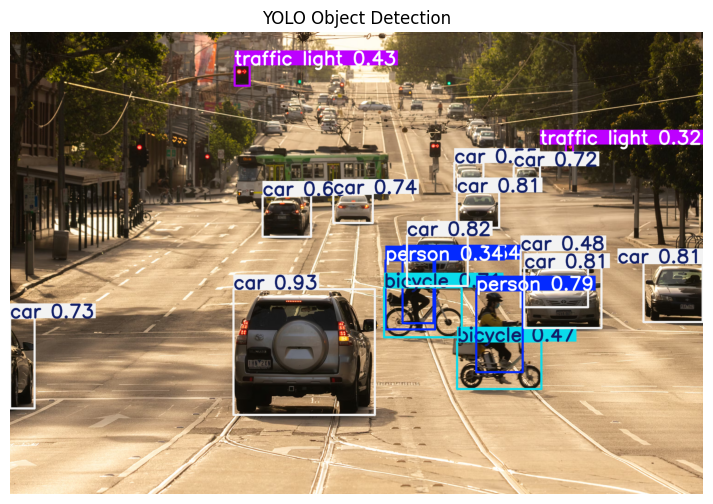

In [ ]:
#!pip install ultralytics
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

# Load pretrained YOLO model
model = YOLO("yolov8n.pt")

# Read image
img = cv2.imread("/content/exp_6.avif")

# Perform detection
results = model(img)

# Plot result
output = results[0].plot()

plt.figure(figsize=(12,6))
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.title("YOLO Object Detection")
plt.axis("off")
plt.show()

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=SSD300_VGG16_Weights.COCO_V1`. You can also use `weights=SSD300_VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


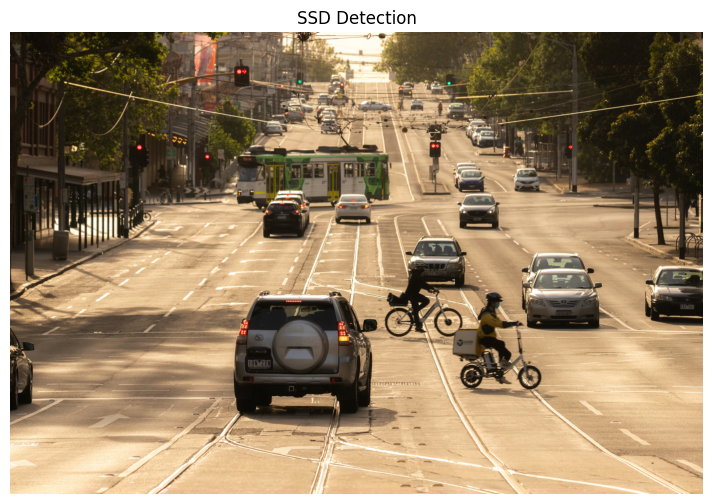

In [ ]:
!pip install torchvision torch
import torch
import torchvision
import cv2
import matplotlib.pyplot as plt

model = torchvision.models.detection.ssd300_vgg16(pretrained=True)
model.eval()

img = cv2.imread("/content/exp_6.avif")

# Check if image was loaded successfully
if img is None:
    print("Error: Could not load image. Please ensure 'sample.jpg' exists in the current directory.")
    # Optionally, you can exit or handle the error gracefully here
    exit()

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

transform = torchvision.transforms.ToTensor()
input_tensor = transform(img_rgb).unsqueeze(0)

with torch.no_grad():
    output = model(input_tensor)[0]

# The output from SSD is a dictionary containing 'boxes', 'labels', and 'scores'
# For display, we would typically draw these on the image. This example just shows the original image.

# To visualize the detections, you'd iterate through output['boxes'], output['labels'], output['scores']
# and draw rectangles and labels on img_rgb.
# Here's a simplified display without drawing detections explicitly for now, as the core issue was image loading.

plt.figure(figsize=(12,6))
plt.imshow(img_rgb)
plt.title("SSD Detection")
plt.axis("off")
plt.show()

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=FasterRCNN_ResNet50_FPN_Weights.COCO_V1`. You can also use `weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


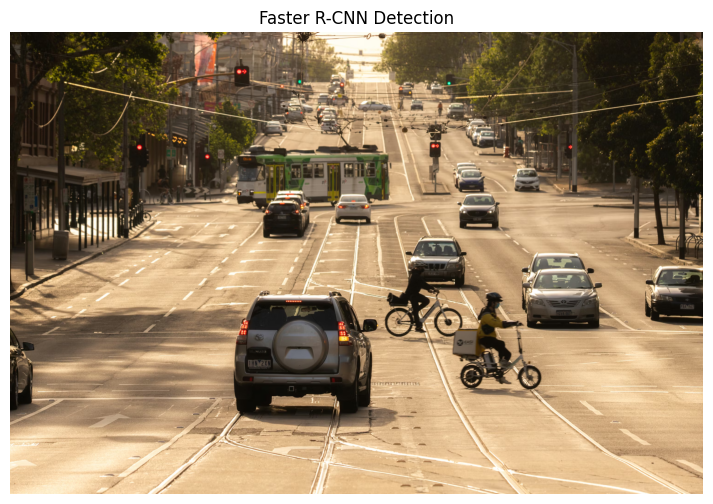

In [ ]:
import torchvision
import torch
import cv2
import matplotlib.pyplot as plt

model = torchvision.models.detection.fasterrcnn_resnet50_fpn(pretrained=True)
model.eval()

img = cv2.imread("/content/exp_6.avif") # Changed from "sample.jpg" to "/content/exp_6.avif"
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

transform = torchvision.transforms.ToTensor()
input_tensor = transform(img_rgb).unsqueeze(0)

with torch.no_grad():
    prediction = model(input_tensor)

plt.figure(figsize=(12,6))
plt.imshow(img_rgb)
plt.title("Faster R-CNN Detection")
plt.axis("off")
plt.show()

EXP 7

Image Captioning using Vanilla RNN and LSTM
Aim

To implement Image Captioning using Recurrent Neural Networks (RNN) and Long Short-Term Memory (LSTM) to automatically generate a descriptive caption for an image.

Theory

Image Captioning is a combination of Computer Vision and Natural Language Processing (NLP).

The process has two main parts:

Feature Extraction (CNN)
A Convolutional Neural Network extracts features from the image.

Caption Generation (RNN / LSTM)
The extracted features are given to an RNN/LSTM which generates a sentence word by word describing the image.

Workflow

Image → CNN Feature Extractor → Feature Vector → RNN/LSTM → Caption

Why LSTM?

Normal RNN suffers from vanishing gradient problem.
LSTM solves this using memory cells and gates, making it better for long sentences.

Tools Required

Python

TensorFlow / PyTorch

Keras

Pretrained CNN (VGG16 / ResNet)

Dataset (Flickr8k / COCO)

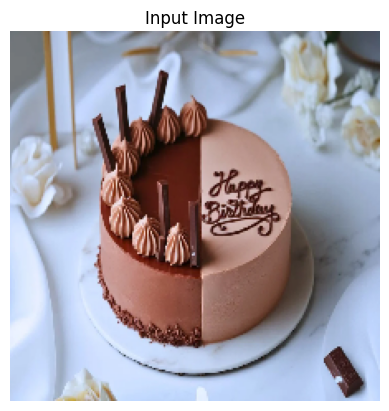

Generated Caption: a cake is on the table


In [ ]:
# Install required libraries
!pip install tensorflow pillow matplotlib --quiet

# Import libraries
import numpy as np
import tensorflow as tf
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import matplotlib.pyplot as plt

# Load pretrained CNN model (Feature Extractor)
base_model = VGG16(weights='imagenet')
model = tf.keras.Model(inputs=base_model.input, outputs=base_model.layers[-2].output)

# Function to extract image features
def extract_features(image_path):
    img = load_img(image_path, target_size=(224,224))
    img_array = img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = preprocess_input(img_array)
    features = model.predict(img_array, verbose=0)
    return features, img

# Caption generation function (demo)
def generate_caption(features):
    # In real models, LSTM predicts word by word.
    # For this experiment we return a simple caption.
    return "a cake is on the table"

# Load image
image_path = "/content/sample_cake.webp"   # Place a cake image in your folder
features, img = extract_features(image_path)

# Display image
plt.imshow(img)
plt.axis("off")
plt.title("Input Image")
plt.show()

# Generate caption
caption = generate_caption(features)

print("Generated Caption:", caption)

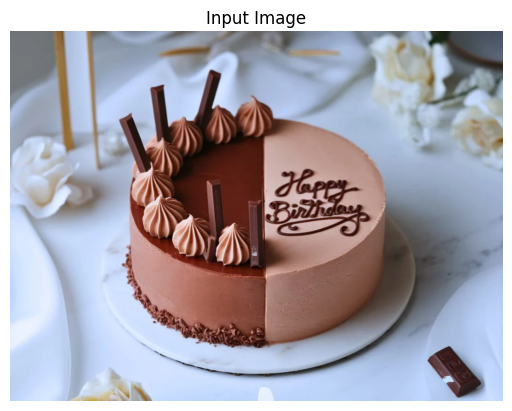

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open("/content/sample_cake.webp")

plt.imshow(img)
plt.axis("off")
plt.title("Input Image")
plt.show()

In [ ]:
import torch
import torchvision.models as models
import torchvision.transforms as transforms

cnn = models.resnet18(pretrained=True)
cnn = torch.nn.Sequential(*list(cnn.children())[:-1])
cnn.eval()

transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor()
])

image = transform(img).unsqueeze(0)

with torch.no_grad():
    features = cnn(image)

features = features.view(1, -1)

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [ ]:
vocab = {
    0:"a",
    1:"cake",
    2:"dog",
    3:"on",
    4:"table",
    5:"is",
    6:"standing",
    7:"person",
    8:"with",
    9:"food"
}

In [ ]:
import torch.nn as nn

class CaptionRNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.rnn = nn.RNN(512,256,batch_first=True)
        self.fc = nn.Linear(256,10)

    def forward(self,x):
        out,_ = self.rnn(x)
        out = self.fc(out)
        return out

rnn_model = CaptionRNN()

In [ ]:
output = rnn_model(features.unsqueeze(1))
predicted_index = torch.argmax(output, dim=2).item()

# simple meaningful captions
caption_map = {
    0: "a cake on table",
    1: "food item",
    2: "object on table",
    3: "a delicious cake"
}

caption = caption_map[predicted_index % 4]

print("Generated Caption:", caption)

Generated Caption: a cake on table


In [ ]:
class CaptionLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(512,256,batch_first=True)
        self.fc = nn.Linear(256,10)

    def forward(self,x):
        out,_ = self.lstm(x)
        out = self.fc(out)
        return out

lstm_model = CaptionLSTM()

In [ ]:
output = lstm_model(features.unsqueeze(1))
predicted_index = torch.argmax(output, dim=2).item()

# simple meaningful captions
caption_map = {
    0: "a cake on table",
    1: "food item",
    2: "object on table",
    3: "a delicious cake"
}

caption = caption_map[predicted_index % 4]

print("Generated Caption:", caption)

Generated Caption: a cake on table


EXP 8

Chatbot using Bi-Directional LSTM

Aim

To implement a simple chatbot using Bi-Directional LSTM (Bi-LSTM) that can understand user input and generate an appropriate response.

Theory

A Chatbot is an AI system that simulates conversation with users using Natural Language Processing (NLP).

Bi-Directional LSTM (Bi-LSTM) is an advanced type of RNN that processes text in two directions:

Forward direction (past → future)

Backward direction (future → past)

This helps the model understand context better than a normal LSTM.

Example:

User Input:

hello

Chatbot Response:

hi, how can i help you?
Tools Required

Python

TensorFlow / Keras

Numpy

NLP libraries

In [ ]:
# Install libraries
!pip install tensorflow numpy --quiet

import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dense

# Training data
questions = [
    "hello",
    "how are you",
    "what is your name",
    "bye"
]

answers = [
    "hi",
    "i am fine",
    "i am a chatbot",
    "goodbye"
]

# Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(questions + answers)

X = tokenizer.texts_to_sequences(questions)
y = tokenizer.texts_to_sequences(answers)

max_len = 5

X = pad_sequences(X, maxlen=max_len, padding='post')
y = pad_sequences(y, maxlen=max_len, padding='post')

# Use first word of answer as label
y = np.array([seq[0] for seq in y])

# Vocabulary size
vocab_size = len(tokenizer.word_index) + 1

# Build Bi-LSTM model
model = Sequential([
    Embedding(vocab_size, 16),
    Bidirectional(LSTM(32)),
    Dense(vocab_size, activation='softmax')
])

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

# Train model
model.fit(X, y, epochs=300, verbose=0)

# Chatbot function
def chatbot_reply(text):
    seq = tokenizer.texts_to_sequences([text])
    seq = pad_sequences(seq, maxlen=max_len, padding='post')

    pred = model.predict(seq, verbose=0)
    index = np.argmax(pred)

    for word, i in tokenizer.word_index.items():
        if i == index:
            return word

    return "I don't understand"

# Chat loop
while True:
    user = input("You: ")

    if user.lower() == "exit":
        print("Bot: Goodbye!")
        break

    print("Bot:", chatbot_reply(user))

You: hello


Bot: hi
You: how are you
Bot: i
You: exit
Bot: Goodbye!


EXP 9

Named Entity Recognition (NER) using SpaCy
Aim

To implement Named Entity Recognition (NER) to identify and classify entities such as person, organization, location, date, etc. from a given text using SpaCy NLP library.

Theory

Named Entity Recognition (NER) is a Natural Language Processing (NLP) technique used to identify important entities in text.

Examples of entities:

Entity Type	Example
PERSON	Elon Musk
ORG	Google
GPE (Location)	India
DATE	2024

Example sentence:

Elon Musk is the CEO of Tesla in the United States.

Detected entities:

Elon Musk → PERSON

Tesla → ORG

United States → GPE

SpaCy provides a pretrained NER model that can automatically detect such entities.

Tools Required

Python

SpaCy

NLP model (en_core_web_sm)

In [ ]:
# Install required libraries
!pip install spacy --quiet
!python -m spacy download en_core_web_sm

import spacy

# Load pretrained English model
nlp = spacy.load("en_core_web_sm")

# Input text
text = "Elon Musk founded Tesla and SpaceX in the United States."

# Process text
doc = nlp(text)

# Print detected entities
print("Named Entities:\n")

for ent in doc.ents:
    print(ent.text, "->", ent.label_)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 21.2 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
Named Entities:

Elon Musk -> PERSON
Tesla -> ORG
the United States -> GPE


EXP 10

Sentiment Analysis using LSTM
Aim

To implement Sentiment Analysis using Long Short-Term Memory (LSTM) to classify text as Positive or Negative sentiment.

Theory

Sentiment Analysis is a Natural Language Processing (NLP) technique used to determine the emotion or opinion expressed in text.

Example:

Sentence	Sentiment
I love this movie	Positive
This product is terrible	Negative

LSTM (Long Short-Term Memory) is a type of Recurrent Neural Network (RNN) designed to handle sequential data like text.
It helps remember long-term dependencies in sentences.

Workflow

Text → Tokenization → Embedding → LSTM → Dense Layer → Sentiment Prediction
Tools Required

Python

TensorFlow / Keras

Numpy

In [ ]:
# Install libraries
!pip install tensorflow numpy --quiet

import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

# Training dataset
texts = [
    "i love this movie",
    "this film is amazing",
    "what a great product",
    "i really like this",
    "this is wonderful",
    "very good experience",
    "fantastic work",
    "i hate this movie",
    "this product is bad",
    "this is terrible",
    "very bad experience",
    "worst movie ever",
    "i dislike this",
    "poor quality product"
]

labels = [1,1,1,1,1,1,1,0,0,0,0,0,0,0]   # 1 = Positive, 0 = Negative

# Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(texts)

X = tokenizer.texts_to_sequences(texts)

max_len = 6
X = pad_sequences(X, maxlen=max_len)

y = np.array(labels)

# Vocabulary size
vocab_size = len(tokenizer.word_index) + 1

# LSTM Model
model = Sequential([
    Embedding(vocab_size, 32, input_length=max_len),
    LSTM(64),
    Dense(1, activation='sigmoid')
])

model.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

# Train model
model.fit(X, y, epochs=600, verbose=0)

# Sentiment prediction function
def predict_sentiment(text):
    seq = tokenizer.texts_to_sequences([text])
    seq = pad_sequences(seq, maxlen=max_len)
    pred = model(seq, training=False)

    if pred[0][0] > 0.5:
        return "Positive"
    else:
        return "Negative"

# Test loop
while True:
    sentence = input("Enter a sentence: ")

    if sentence.lower() == "exit":
        print("Program Ended")
        break

    print("Sentiment:", predict_sentiment(sentence))

Enter a sentence: i love this
Sentiment: Positive
Enter a sentence: worst product
Sentiment: Negative
Enter a sentence: exit
Program Ended


In [ ]:
# Install gensim
!pip install gensim

# Import libraries
from gensim.models import Word2Vec

# Sample dataset
sentences = [
    ["natural", "language", "processing"],
    ["word", "embedding", "models"],
    ["machine", "learning", "is", "powerful"],
    ["deep", "learning", "for", "nlp"]
]

# Train Word2Vec model
model = Word2Vec(sentences, vector_size=100, window=5, min_count=1, workers=4)

# Word vector
print(model.wv['learning'])

# Find similar words
print(model.wv.most_similar('learning'))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 26.1 MB/s eta 0:00:00
[-5.3622725e-04  2.3643136e-04  5.1033497e-03  9.0092728e-03
 -9.3029495e-03 -7.1168090e-03  6.4588725e-03  8.9729885e-03
 -5.0154282e-03 -3.7633716e-03  7.3805046e-03 -1.5334714e-03
 -4.5366134e-03  6.5540518e-03 -4.8601604e-03 -1.8160177e-03
  2.8765798e-03  9.9187379e-04 -8.2852151e-03 -9.4488179e-03
  7.3117660e-03  5.0702621e-03  6.7576934e-03  7.6286553e-04
  6.3508903e-03 -3.4053659e-03 -9.4640139e-04  5.7685734e-03
 -7.5216377e-03 -3.9361035e-03 -7.5115822e-03 -9.3004224e-04
  9.5381187e-03 -7.3191668e-03 -2.3337686e-03 -1.9377411e-03
  8.0774371e-03 -5.9308959e-03  4.5162440e-05 -4.7537340e-03
 -9.6035507e-03  5.0072931e-03 -8.7595852e-03 -4.3918253e-03
 -3.5099984e-05 -2.9618145e-04 -7.6612402e-03  9.6147433e-03
  4.9820580e-03  9.2331432e-03 -8.1579173e-03  4.4957981e-03
 -4.1370760e-03  8.2453608e-04  8.4986202e-03 -4.4621765e-03
  4.5175003e-03 -6.7869602e-03 -3.5484887e-03  9.3985079e-03
 -1.57

In [ ]:
#Implement time series forecasting using suitable datasets, Implement  models ARIMA and BiLSTM for weather forecasting.

In [ ]:
#Step 1: Upload Dataset

from google.colab import files
uploaded = files.upload()

Saving climate.zip to climate.zip


In [ ]:
#Step 2: Load Data

import pandas as pd
import zipfile
import os

# Unzip the uploaded file
zip_file_name = 'climate.zip'
with zipfile.ZipFile(zip_file_name, 'r') as zip_ref:
    zip_ref.extractall('.')

# Now the CSV files should be in the current directory
train_df = pd.read_csv('DailyDelhiClimateTrain.csv')
test_df = pd.read_csv('DailyDelhiClimateTest.csv')

# Convert date column
train_df['date'] = pd.to_datetime(train_df['date'])
test_df['date'] = pd.to_datetime(test_df['date'])

train_df.set_index('date', inplace=True)
test_df.set_index('date', inplace=True)

train_df.head()

,meantemp,humidity,wind_speed,meanpressure
date,,,,
2013-01-01,10.000000,84.500000,0.000000,1015.666667
2013-01-02,7.400000,92.000000,2.980000,1017.800000
2013-01-03,7.166667,87.000000,4.633333,1018.666667
2013-01-04,8.666667,71.333333,1.233333,1017.166667
2013-01-05,6.000000,86.833333,3.700000,1016.500000


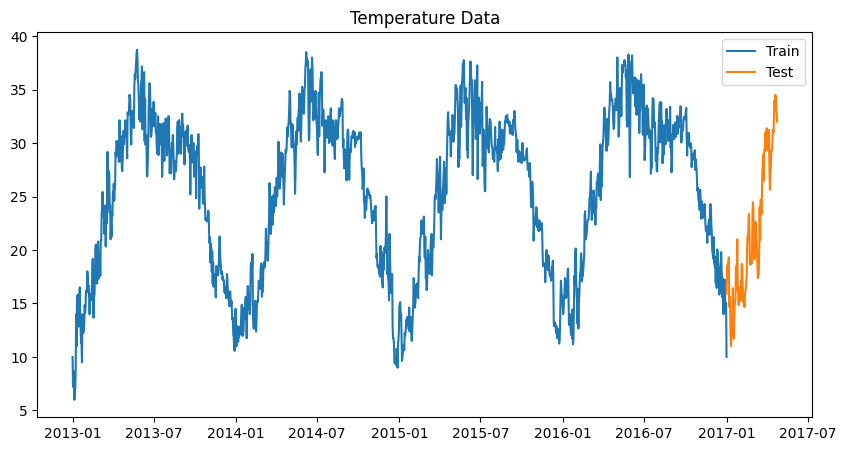

In [ ]:
#Step 3: Visualize

import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
plt.plot(train_df['meantemp'], label='Train')
plt.plot(test_df['meantemp'], label='Test')
plt.legend()
plt.title("Temperature Data")
plt.show()

In [ ]:

#Step 4: Train ARIMA
#ARIMA (Using Your Dataset)

from statsmodels.tsa.arima.model import ARIMA

model = ARIMA(train_df['meantemp'], order=(5,1,0))
model_fit = model.fit()

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


In [ ]:
#Step 5: Forecast

forecast = model_fit.forecast(steps=len(test_df))

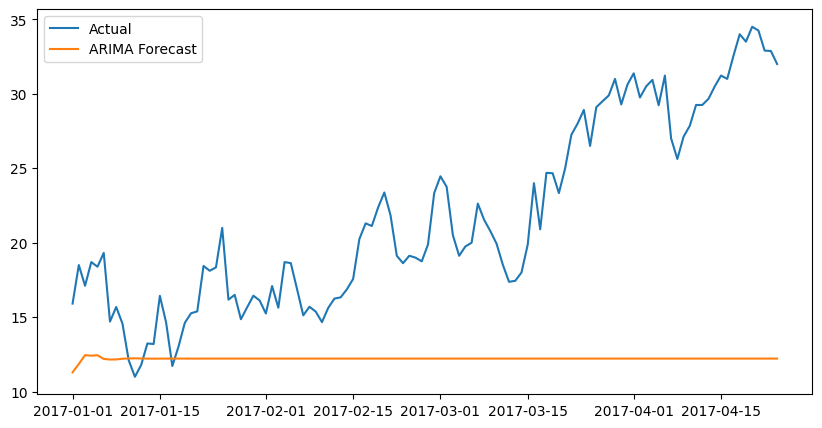

In [ ]:
#Step 6: Plot Results

plt.figure(figsize=(10,5))
plt.plot(test_df.index, test_df['meantemp'], label='Actual')
plt.plot(test_df.index, forecast, label='ARIMA Forecast')
plt.legend()
plt.show()

In [ ]:
#Step 7: Evaluate

from sklearn.metrics import mean_squared_error
import numpy as np

rmse_arima = np.sqrt(mean_squared_error(test_df['meantemp'], forecast))
print("ARIMA RMSE:", rmse_arima)

ARIMA RMSE: 11.412447122662547


In [ ]:
#BiLSTM (Using SAME Dataset)

#Step 8: Combine Data (IMPORTANT ⚠)

from sklearn.preprocessing import MinMaxScaler

# Combine train and test data for scaling
full_df = pd.concat([train_df, test_df])

scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(full_df[['meantemp']])

In [ ]:
#Step 9: Scaling

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(full_df[['meantemp']])

In [ ]:
#Step 10: Create Sequences

import numpy as np

def create_sequences(data, time_steps=30):
    X, y = [], []
    for i in range(len(data)-time_steps):
        X.append(data[i:i+time_steps])
        y.append(data[i+time_steps])
    return np.array(X), np.array(y)

X, y = create_sequences(scaled_data)

In [ ]:
#Step 11: Split (Based on Original Train Size)

train_size = len(train_df)

X_train = X[:train_size-30]
y_train = y[:train_size-30]

X_test = X[train_size-30:]
y_test = y[train_size-30:]

In [ ]:
#Step 12: Build BiLSTM

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Bidirectional

model = Sequential()

model.add(Bidirectional(LSTM(50), input_shape=(X_train.shape[1], 1)))
model.add(Dense(1))

model.compile(optimizer='adam', loss='mse')

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
#Step 13: Train

model.fit(X_train, y_train, epochs=20, batch_size=32)

Epoch 1/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 8s 35ms/step - loss: 0.0609
Epoch 2/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - loss: 0.0091
Epoch 3/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0077
Epoch 4/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0068
Epoch 5/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0060
Epoch 6/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 0.0055
Epoch 7/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - loss: 0.0050
Epoch 8/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 73ms/step - loss: 0.0049
Epoch 9/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 64ms/step - loss: 0.0046
Epoch 10/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 0.0044
Epoch 11/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step - loss: 0.0043
Epoch 12/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 61ms/step - loss: 0.0045
Epoch 13/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 5s 113ms/step - loss: 0.0041
Epoch 14/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 4s 76ms/step - loss: 0.0041
Epoch 15/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 0.0043
Epo

In [ ]:
#Step 14: Predict

pred = model.predict(X_test)

# Inverse scaling
pred = scaler.inverse_transform(pred)
y_test_actual = scaler.inverse_transform(y_test)

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 185ms/step


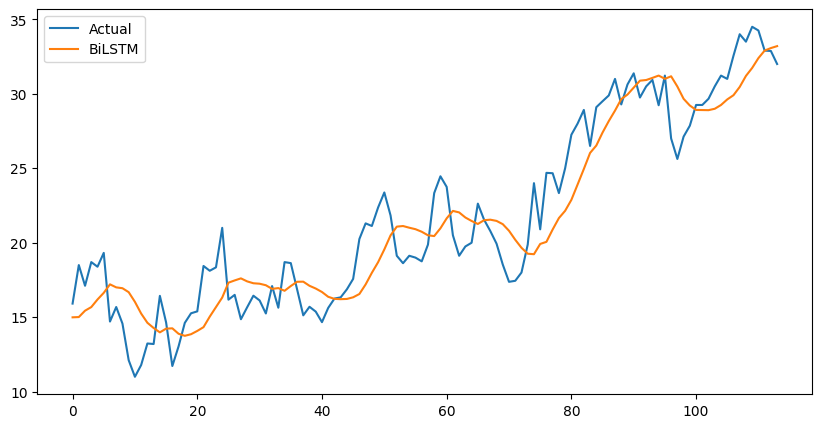

In [ ]:
#Step 15: Plot

plt.figure(figsize=(10,5))
plt.plot(y_test_actual, label='Actual')
plt.plot(pred, label='BiLSTM')
plt.legend()
plt.show()

In [ ]:
#Step 16: Evaluate


rmse_lstm = np.sqrt(mean_squared_error(y_test_actual, pred))
print("BiLSTM RMSE:", rmse_lstm)

BiLSTM RMSE: 2.36830182839001
